# 05 — U-Net–ResNet34: tiền huấn luyện và thí nghiệm đối chứng

Thí nghiệm M2 sử dụng U-Net với encoder ResNet34 khởi tạo từ ImageNet và tinh chỉnh toàn bộ encoder–decoder trên 700 ảnh Kvasir train. Tập validation gồm 150 ảnh phục vụ chọn checkpoint. Tập test nội bộ và CVC-ClinicDB được giữ cho đánh giá cuối.

Kiến trúc được triển khai bằng `segmentation_models_pytorch==0.5.0`. Decoder có các mức 256/128/64/32/16, BatchNorm và upsampling nearest; cấu trúc này khác U-Net tự cài M1. Mô hình xuất logits một kênh, không sigmoid ở lớp cuối khi tính loss. Trọng số encoder lấy từ torchvision ResNet34 ImageNet1K V1, được nạp sau khi khởi tạo mô hình để giữ cùng trạng thái decoder/head giữa M2 và A1 với cùng seed.

Notebook trình bày môi trường, thiết lập thí nghiệm, kết quả và so sánh với M1. Thực thi toàn bộ notebook sẽ bắt đầu một lượt M2 mới; A1 chỉ được thực hiện khi bật biến tương ứng. Lần tạo M2 đầu tiên cần Internet nếu trọng số chưa có trong cache. Các nhận xét định lượng bên dưới gắn với lượt M2 `20261127T051218Z_full_seed42_c3094e` và lượt M1 được nêu trong bảng so sánh.

Tài liệu triển khai: [SMP U-Net](https://smp.readthedocs.io/en/stable/_modules/segmentation_models_pytorch/decoders/unet/model.html), [torchvision ResNet34](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet34.html).

## Môi trường thực thi

Ô dưới xác định Python của kernel và phiên bản các thư viện chính. Cài đặt sử dụng chính Python này để tránh khác biệt giữa môi trường notebook và terminal.

Khi thiếu thư viện, đặt `INSTALL_DEPENDENCIES=True`, thực thi riêng ô cài đặt rồi khởi động lại kernel. Sau đó đưa biến về `False` và kiểm tra môi trường trước khi huấn luyện. Các phụ thuộc được khai báo trong `requirements-training.txt`; bản PyTorch CPU/CUDA được lựa chọn theo phần cứng và hướng dẫn trong README.

In [1]:
import sys
import subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

start = Path.cwd().resolve()
project_root = next((p for p in (start, *start.parents)
                     if (p / 'requirements-training.txt').is_file() and (p / 'src').is_dir()), None)
if project_root is None:
    raise FileNotFoundError('Mở notebook trong repository.')

print('Python của kernel:', sys.executable)
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r',
                           str(project_root / 'requirements-training.txt')])
    print('Cài đặt hoàn tất. Restart Kernel trước khi import thư viện hoặc train.')

missing = []
for package in ('torch', 'torchvision', 'segmentation-models-pytorch', 'PyYAML', 'matplotlib'):
    try:
        print(f'{package}: {version(package)}')
    except PackageNotFoundError:
        missing.append(package)
        print(f'{package}: chưa cài trong kernel này')
if missing:
    raise RuntimeError('Thiếu thư viện. Bật INSTALL_DEPENDENCIES=True và chạy lại riêng ô này, sau đó Restart Kernel.')


Python của kernel: d:\anaconda\envs\data_processing\python.exe
torch: 2.9.1+cu126
torchvision: 0.24.1+cu126
segmentation-models-pytorch: 0.5.0
PyYAML: 6.0.2
matplotlib: 3.10.7


In [2]:
import sys
from pathlib import Path
start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents) if (p / 'src/datasets').is_dir() and (p / 'README.md').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Mở notebook trong repository.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import torch
import segmentation_models_pytorch as smp
from PIL import Image
from IPython.display import display
from src.training import run_training, select_device
from src.utils import load_config
print('Torch:', torch.__version__, '| SMP:', smp.__version__, '| Device:', select_device())
config = load_config(PROJECT_ROOT / 'configs/pretrained_unet.yaml')
print('Model:', config['model'])
print('Train:', config['training'])

Torch: 2.9.1+cu126 | SMP: 0.5.0 | Device: cuda
Model: {'name': 'pretrained_unet', 'encoder_weights': 'imagenet', 'decoder_channels': [256, 128, 64, 32, 16], 'output_channels': 1}
Train: {'device': 'auto', 'amp': True, 'optimizer': 'Adam', 'learning_rate': 0.0001, 'weight_decay': 0.0, 'max_epochs': 200, 'loss': 'bce_dice', 'bce_weight': 1.0, 'dice_weight': 1.0, 'ignore_padding': True, 'scheduler': {'name': 'ReduceLROnPlateau', 'monitor': 'val_dice', 'mode': 'max', 'factor': 0.5, 'patience': 5, 'min_lr': 1e-06}, 'early_stopping_patience': 20, 'checkpoint_metric': 'val_dice'}


## 5.1 — Thiết kế so sánh

M2 sử dụng cùng split, letterbox 256×256, chuẩn hóa ImageNet, augmentation lật/xoay, BCE+soft Dice loại padding và phương pháp validation ở kích thước gốc của M1. Cấu hình gồm Adam LR 1e-4, batch size 8, tối đa 200 epoch, scheduler và early stopping theo validation Dice. Khi hòa điểm, giữ checkpoint sớm hơn. Mixed precision được sử dụng trên CUDA.

M2 không khởi tạo từ checkpoint M1. Trọng số ImageNet cung cấp khởi tạo cho encoder; cả encoder và decoder tiếp tục được tối ưu cho nhiệm vụ phân vùng polyp. Metadata lưu nguồn trọng số, hash trạng thái khởi tạo, phiên bản thư viện, cấu hình và hash split để đối chiếu điều kiện thí nghiệm.

M1–M2 là so sánh hai cấu hình khác nhau cả kiến trúc và pretraining. Để khảo sát riêng ảnh hưởng của khởi tạo encoder, thí nghiệm đối chứng A1 sử dụng đúng kiến trúc M2 nhưng không nạp trọng số ImageNet. Trạng thái rà dữ liệu chưa hoàn tất được giữ là `provisional` trong metadata.

In [3]:
m2_run = run_training(PROJECT_ROOT, 'configs/pretrained_unet.yaml', mode='full', progress=False)

Run: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M2\20261127T051218Z_full_seed42_c3094e
Mode=full, device=cuda, AMP=True, counts={'train': 700, 'val': 150}
NOTE: duplicate screening/review is not current. This run is provisional; finish notebook 02 before final reporting.
Epoch 1/200 | train_loss=1.1295 | val_loss=0.8717 | val_dice=0.6927 | val_iou=0.5572 | lr=0.0001
Epoch 2/200 | train_loss=0.8246 | val_loss=0.7284 | val_dice=0.7894 | val_iou=0.6796 | lr=0.0001
Epoch 3/200 | train_loss=0.6967 | val_loss=0.5776 | val_dice=0.8514 | val_iou=0.7705 | lr=0.0001
Epoch 4/200 | train_loss=0.5806 | val_loss=0.4919 | val_dice=0.8437 | val_iou=0.7573 | lr=0.0001
Epoch 5/200 | train_loss=0.4875 | val_loss=0.4487 | val_dice=0.8606 | val_iou=0.7850 | lr=0.0001
Epoch 6/200 | train_loss=0.4302 | val_loss=0.4399 | val_dice=0.8556 | val_iou=0.7764 | lr=0.0001
Epoch 7/200 | train_loss=0.3753 | val_loss=0.3851 | val_dice=0.8560 | val_iou=0.7777 | lr=0.0001
Epoch 8/200 | train_loss=0.3432 | val_loss

## 5.2 — Kết quả M2 và minh họa dự đoán

Ô dưới trình bày checkpoint được lựa chọn, nguồn trọng số, learning curve và overlay dự đoán. Các đường biểu diễn gồm loss, Dice, IoU và learning rate. Metric train được đo trên vùng hợp lệ ở độ phân giải đầu vào; metric validation được đo ở kích thước ảnh gốc.

Overlay đối chiếu ground truth và dự đoán từ checkpoint tốt nhất theo validation Dice. Các hình là minh họa trên một số mẫu, không thay thế đánh giá trên toàn bộ tập. Kiến trúc thực tế của M2 được lưu tại `architecture.txt`, tách biệt với sơ đồ U-Net M1.

Run: D:\DHCN\HK5\DL\Medical-Image-Segmentation\results\M2\20261127T051218Z_full_seed42_c3094e
Best epoch: 101
Best validation Dice: 0.901927122262617
Weights: {'library': 'segmentation_models_pytorch', 'version': '0.5.0', 'encoder': 'resnet34', 'encoder_weights': 'imagenet', 'decoder_channels': [256, 128, 64, 32, 16], 'decoder_normalization': 'batchnorm', 'decoder_interpolation': 'nearest', 'init_seed': 42, 'decoder_initial_sha256': 'f7ea124b954bec700021e73bdf206f9c590940741f084048d211f5c374fdf5e8', 'head_initial_sha256': 'd61a0da86a7d9e5ae30247f2180ffba08dad708848e60456e57e1ee1f9ceff45', 'weights_url': 'https://download.pytorch.org/models/resnet34-b627a593.pth', 'encoder_initial_sha256': 'ea3c2233b863181ed0d6e7e5e671f0894f517c95aab5a22613499f1710192172'}


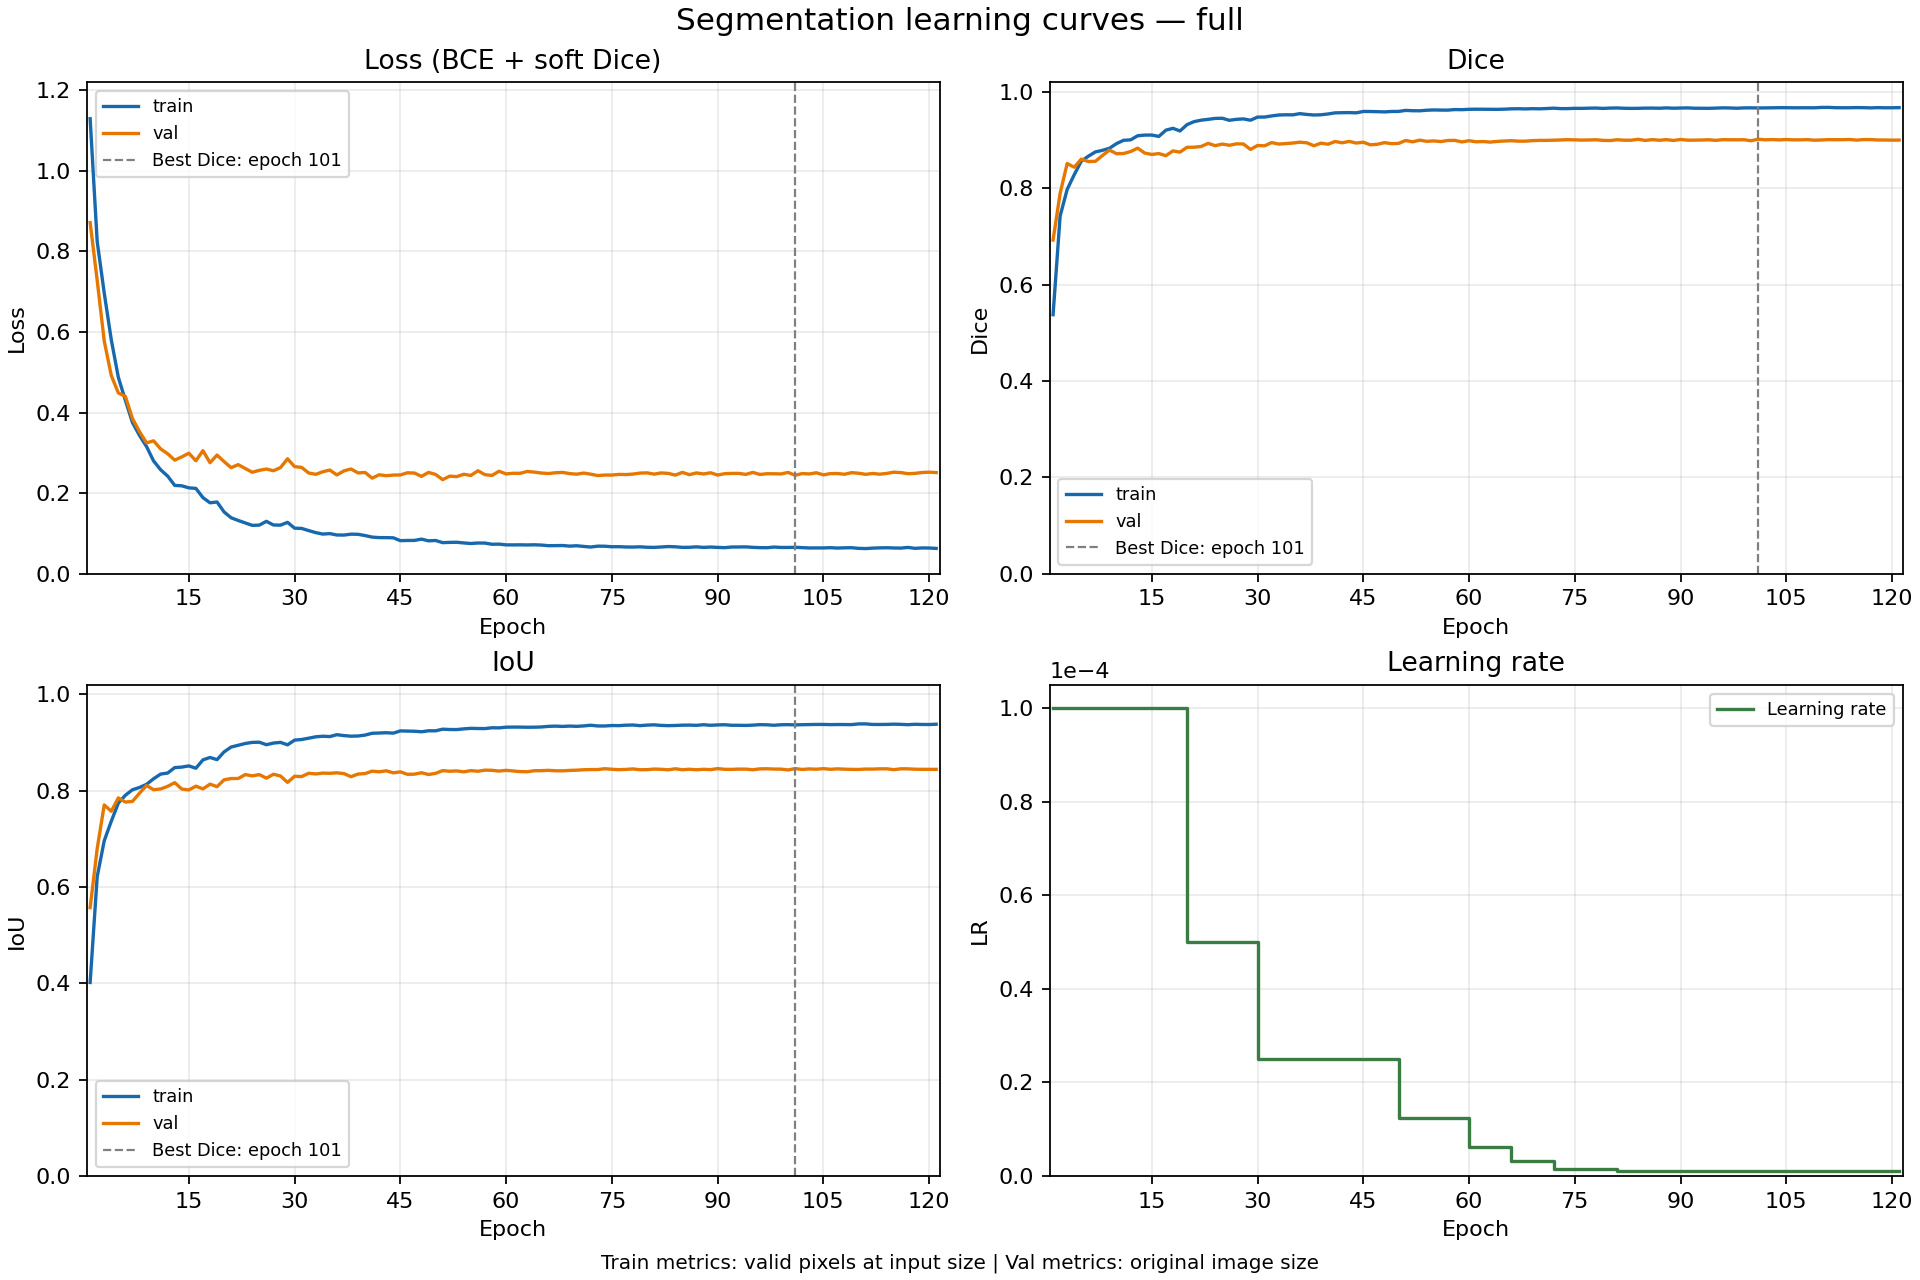

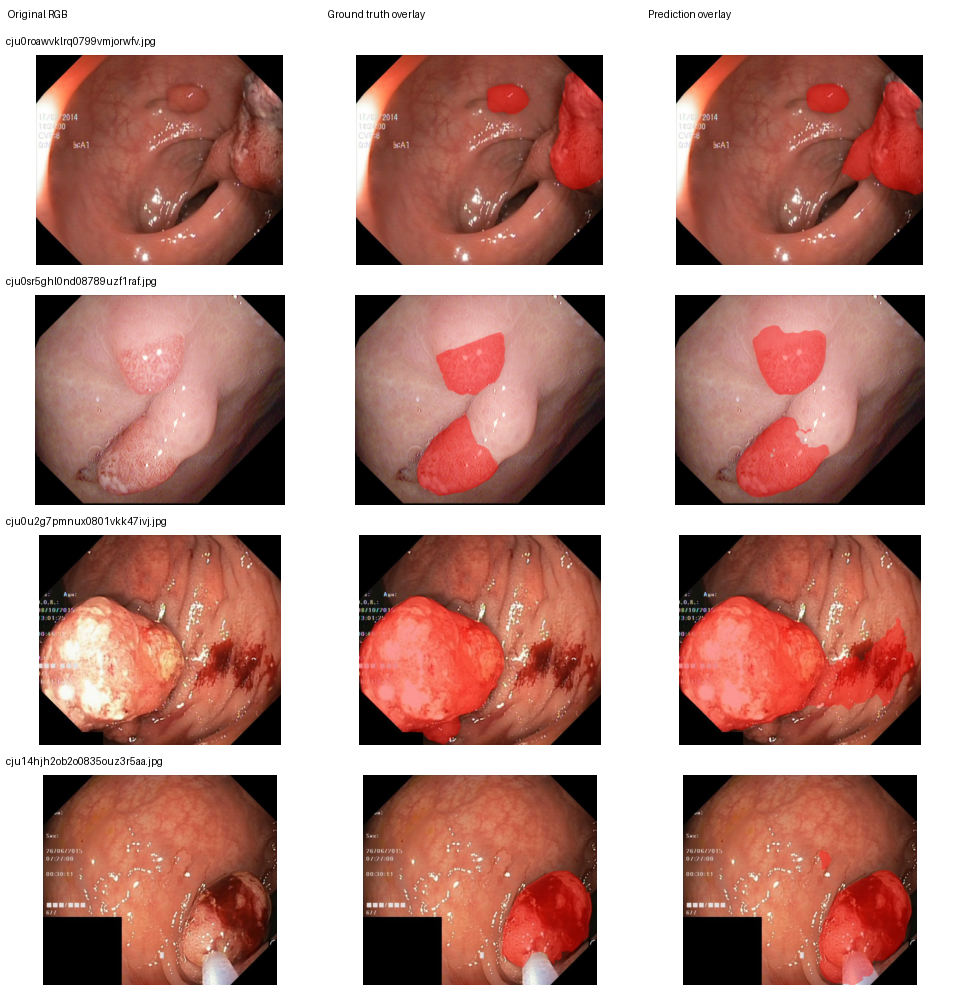

In [4]:
from src.visualization import plot_run_history
print('Run:', m2_run['run_dir'])
print('Best epoch:', m2_run['metadata']['best_epoch'])
print('Best validation Dice:', m2_run['metadata']['best_dice'])
print('Weights:', m2_run['metadata']['model_provenance'])
for path in (plot_run_history(m2_run['run_dir']), m2_run['run_dir'] / 'predictions_best.png'):
    with Image.open(path) as image:
        display(image.copy())

### Nhận xét quá trình học của M2

Lượt `20261127T051218Z_full_seed42_c3094e` hoàn tất **121 epoch**; checkpoint được lựa chọn tại **epoch 101**, với validation Dice **0.9019 (90.19%)** và IoU **0.8460 (84.60%)**. Early stopping xảy ra sau 20 epoch tiếp theo không vượt Dice tốt nhất. IoU được báo cáo tại cùng checkpoint chọn theo Dice.

| Mốc | Train loss | Validation loss | Validation Dice | Validation IoU |
| --- | ---: | ---: | ---: | ---: |
| Epoch 1 | 1.1295 | 0.8717 | 0.6927 | 0.5572 |
| Epoch 10 | 0.2798 | 0.3298 | 0.8718 | 0.8021 |
| Epoch 50 | 0.0823 | 0.2463 | 0.8932 | 0.8360 |
| Epoch 101 — checkpoint được chọn | 0.0654 | 0.2442 | 0.9019 | 0.8460 |
| Epoch 121 — kết thúc | 0.0626 | 0.2510 | 0.9001 | 0.8443 |

Điểm validation tăng nhanh ở giai đoạn đầu: tại epoch 10, Dice đạt 0.8718; từ epoch 50 đến checkpoint tốt nhất, mức tăng còn khoảng 0.0088. Diễn biến này cho thấy lợi ích giảm dần khi tiếp tục huấn luyện trong cấu hình đang xét. Sau epoch 101, train loss vẫn giảm nhẹ nhưng validation loss và Dice không tốt hơn checkpoint đã lưu, nên dừng sớm tránh kéo dài quá trình mà chưa có cải thiện đo được.

Trung vị Dice đạt **0.9556**; **116/150 ảnh có Dice ≥0.9**, nhưng vẫn còn **7/150 ảnh có Dice <0.5**. Vì vậy, điểm trung bình cao hơn không đồng nghĩa mọi ảnh đều được phân vùng chính xác. Cần phân tích các mẫu điểm thấp bằng ground truth, overlay và đặc điểm ảnh trước khi kết luận nguyên nhân.

## 5.3 — Thí nghiệm đối chứng A1

A1 sử dụng cùng kiến trúc encoder–decoder với M2 nhưng encoder được khởi tạo ngẫu nhiên. Với cùng seed, decoder và segmentation head có trạng thái khởi tạo giống nhau; hash trong metadata hỗ trợ kiểm chứng. Split, tiền xử lý, augmentation, loss, lịch huấn luyện và tiêu chí lựa chọn checkpoint được giữ nguyên.

Ô dưới chỉ thực hiện một lượt huấn luyện A1 khi `RUN_A1=True`. Trong output hiện tại, A1 chưa được chạy, vì vậy chưa có kết quả định lượng để tách ảnh hưởng pretraining khỏi ảnh hưởng kiến trúc. Không thay thế kết quả A1 bằng số liệu của U-Net M1 vì hai kiến trúc khác nhau.

In [5]:
RUN_A1 = False
if RUN_A1:
    a1_run = run_training(PROJECT_ROOT, 'configs/pretrained_unet_random.yaml', mode='full', progress=False)

## 5.4 — Bảng so sánh validation

Ô dưới đọc các lượt huấn luyện đầy đủ đã hoàn tất, chọn lượt được cập nhật mới nhất của mỗi mô hình và tổng hợp metric tại checkpoint được lựa chọn. Tiêu chí này chọn lượt thực nghiệm để trình bày, không phải chọn lượt có điểm cao nhất qua nhiều lần thử.

Phép đối chiếu kiểm tra split, seed, cấu hình dữ liệu, DataLoader, huấn luyện và đánh giá. Bảng ghi trạng thái rà dữ liệu để bảo toàn giới hạn diễn giải. Việc đọc bảng không thực hiện huấn luyện hoặc suy luận trên test/ClinicDB. Có thể chạy ô này độc lập sau khi khởi động lại kernel.

In [6]:
import sys
from pathlib import Path
start = Path.cwd().resolve()
root = next(p for p in (start, *start.parents) if (p / 'src/datasets').is_dir())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.comparison import compare_saved_runs
comparison = compare_saved_runs(root)
from IPython.display import display, Markdown
display(Markdown(comparison))

| Model | Run | Best epoch | Val Dice | Val IoU | Parameters | Seconds | Review |
| --- | --- | ---: | ---: | ---: | ---: | ---: | --- |
| M1 | 20261124T081030Z_full_seed42_e67215 | 107 | 0.7999 | 0.7100 | 7760097 | 3320.6 | provisional |
| M2 | 20261127T051218Z_full_seed42_c3094e | 101 | 0.9019 | 0.8460 | 24436369 | 1580.3 | provisional |

Validation only; no test/external inference. M1/M2 differ in architecture and pretraining.

## 5.5 — Phân tích so sánh M1–M2

Phân tích này sử dụng M1 `20261124T081030Z_full_seed42_e67215` và M2 `20261127T051218Z_full_seed42_c3094e`, cùng seed 42. Hash bốn danh sách split và các cấu hình dữ liệu, DataLoader, huấn luyện, đánh giá của hai lượt đã được đối chiếu và trùng khớp. Mỗi mô hình được đánh giá tại checkpoint có validation Dice cao nhất của chính lượt đó.

| Chỉ tiêu | M1: U-Net tự cài | M2: U-Net–ResNet34 ImageNet |
| --- | ---: | ---: |
| Validation Dice | 0.7999 | 0.9019 |
| Validation IoU | 0.7100 | 0.8460 |
| Trung vị Dice theo ảnh | 0.8820 | 0.9556 |
| Số ảnh có Dice ≥0.9 | 68/150 | 116/150 |
| Số ảnh có Dice <0.5 | 17/150 | 7/150 |
| Số tham số | 7,760,097 | 24,436,369 |
| Epoch được lựa chọn | 107 | 101 |
| Số epoch thực thi | 127 | 121 |
| Thời gian ghi nhận | 55.34 phút | 26.34 phút |

### Chất lượng phân vùng

M2 tăng **10.20 điểm phần trăm Dice** và **13.60 điểm phần trăm IoU** so với M1 trên tập validation. Đây là chênh lệch tuyệt đối theo thang phần trăm, không phải mức tăng tương đối. Trung vị và số ảnh vượt ngưỡng Dice 0.9 cũng cải thiện, trong khi số ảnh dưới 0.5 giảm từ 17 xuống 7.

Đối chiếu từng ID trên cùng 150 ảnh cho thấy M2 có Dice cao hơn M1 ở **127 ảnh** và thấp hơn ở **23 ảnh**. Kết quả hỗ trợ nhận định rằng lợi ích xuất hiện trên phần lớn mẫu, đồng thời cho thấy vẫn có trường hợp M1 tốt hơn. Các cặp mẫu này là cơ sở phù hợp cho phân tích lỗi; số lượng cải thiện không tự chứng minh ý nghĩa thống kê.

### Diễn biến học và chi phí tính toán

Tại epoch 10, validation Dice của M1 là 0.4751, trong khi M2 đạt 0.8718. M2 vì vậy đạt mức chất lượng cao sớm hơn trong hai lượt được ghi nhận. Tuy nhiên, không thể quy toàn bộ khác biệt này cho pretraining vì encoder và decoder của hai mô hình cũng khác nhau.

M2 có số tham số khoảng **3.15 lần** M1 nhưng thời gian toàn lượt được ghi nhận thấp hơn. Hai lượt sử dụng cùng RTX 4050 Laptop GPU và mixed precision; số epoch thực thi khác nhau. Thời gian còn chịu ảnh hưởng của cách triển khai, validation, thao tác ghi tệp và điều kiện hệ thống. Chỉ số này không bao gồm bước tải/khởi tạo trọng số trước khi bắt đầu bộ đếm và không phải benchmark tốc độ suy luận. Do đó, không suy ra mô hình nhiều tham số hơn có chi phí thấp hơn trong mọi điều kiện.

### Phạm vi kết luận

Trong cấu hình và lượt chạy hiện tại, **M2 cho kết quả validation tốt hơn M1**. Chưa thể kết luận riêng mức đóng góp của ImageNet pretraining khi A1 chưa được thực hiện. Cặp A1–M2 cần giữ nguyên kiến trúc và các điều kiện còn lại, đồng thời đối chiếu hash khởi tạo decoder/head.

Hai mô hình mới có một lượt seed 42, chưa có trung bình hoặc độ lệch chuẩn qua nhiều seed. Các điểm trên dùng để chọn checkpoint, chưa phải đánh giá độc lập trên test hoặc ClinicDB. Cả hai lượt vẫn mang trạng thái `provisional` do phương pháp rà dữ liệu chưa được xác nhận cập nhật trong manifest; trạng thái này không có nghĩa đã xác nhận không còn ứng viên chưa rà. Báo cáo cuối cần làm rõ giới hạn dữ liệu và bổ sung đánh giá trên các tập giữ lại sau khi chốt cấu hình.

Các bảng và nhận xét gắn với hai mã lượt thực nghiệm đã nêu. Nếu ô so sánh tự chọn một lượt mới hơn, cần cập nhật phân tích để tránh ghép số liệu của các lượt khác nhau.